### LSTM

### Import Library

In [187]:
import torch 
import torch.nn as nn 
import torch.nn.functional as F 
import torch.optim as optim
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import torchvision 
from torchvision import datasets 
import random

### Set Random Seed

In [188]:
seed = 1234 
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

### Dataset Preparation

In [189]:
import os #512
train_video_dir = "C:/Users/araya/Desktop/vscode/Deep-Learning-Coding/MediaPipe/Data for Different actions/train"
validate_video_dir = "C:/Users/araya/Desktop/vscode/Deep-Learning-Coding/MediaPipe/Data for Different actions/validate"
test_video_dir = "C:/Users/araya/Desktop/vscode/Deep-Learning-Coding/MediaPipe/Data for Different actions/test"
train_video_list = []
validate_video_list = []
test_video_list = []
train_video_list = os.listdir(train_video_dir)
validate_video_list = os.listdir(validate_video_dir)
test_video_list = os.listdir(test_video_dir)

print("Number of train_video_list : ", len(train_video_list))
print("List of train_video_list : ", train_video_list)
print("Number of validate_video_list : ", len(validate_video_list))
print("List of validate_video_list : ", validate_video_list)
print("Number of test_video_list : ", len(test_video_list))
print("List of test_video_list : ", test_video_list)

Number of train_video_list :  120
List of train_video_list :  ['กลัว.mp4', 'กลัว_1.mp4', 'กลัว_4.mp4', 'กิน.mp4', 'กิน_1.mp4', 'กิน_4.mp4', 'ขยัน.mp4', 'ขยัน_1.mp4', 'ขยัน_4.mp4', 'ขอบคุณ.mp4', 'ขอบคุณ_1.mp4', 'ขอบคุณ_4.mp4', 'ขอโทษ.mp4', 'ขอโทษ_1.mp4', 'ขอโทษ_4.mp4', 'ขี้เกียจ.mp4', 'ขี้เกียจ_1.mp4', 'ขี้เกียจ_4.mp4', 'ขโมย.mp4', 'ขโมย_1.mp4', 'ขโมย_4.mp4', 'คิดถึง.mp4', 'คิดถึง_1.mp4', 'คิดถึง_4.mp4', 'คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู.mp4', 'คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_1.mp4', 'คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_4.mp4', 'คุณ.mp4', 'คุณ_1.mp4', 'คุณ_4.mp4', 'คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย.mp4', 'คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_1.mp4', 'คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_4.mp4', 'ง่าย.mp4', 'ง่าย_1.mp4', 'ง่าย_4.mp4', 'ฉลาด.mp4', 'ฉลาด_1.mp4', 'ฉลาด_4.mp4', 'ฉัน.mp4', 'ฉัน_1.mp4', 'ฉัน_4.mp4', 'ฉันตื่นนอน 6 โมงเช้าทุกวัน.mp4', 'ฉันตื่นนอน 6 โมงเช้าทุกวัน_1.mp4', 'ฉันตื่นนอน 6 โมงเช้าทุกวัน_4.mp4', 'ฉันฝึกเขียนภาษาไทย

In [190]:
train_actions = np.array(train_video_list)
print(train_actions)
validate_actions = np.array(validate_video_list)
print(validate_actions)
test_actions = np.array(test_video_list)
print(test_actions)

['กลัว.mp4' 'กลัว_1.mp4' 'กลัว_4.mp4' 'กิน.mp4' 'กิน_1.mp4' 'กิน_4.mp4'
 'ขยัน.mp4' 'ขยัน_1.mp4' 'ขยัน_4.mp4' 'ขอบคุณ.mp4' 'ขอบคุณ_1.mp4'
 'ขอบคุณ_4.mp4' 'ขอโทษ.mp4' 'ขอโทษ_1.mp4' 'ขอโทษ_4.mp4' 'ขี้เกียจ.mp4'
 'ขี้เกียจ_1.mp4' 'ขี้เกียจ_4.mp4' 'ขโมย.mp4' 'ขโมย_1.mp4' 'ขโมย_4.mp4'
 'คิดถึง.mp4' 'คิดถึง_1.mp4' 'คิดถึง_4.mp4'
 'คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู.mp4'
 'คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_1.mp4'
 'คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_4.mp4' 'คุณ.mp4'
 'คุณ_1.mp4' 'คุณ_4.mp4' 'คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย.mp4'
 'คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_1.mp4'
 'คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_4.mp4' 'ง่าย.mp4' 'ง่าย_1.mp4'
 'ง่าย_4.mp4' 'ฉลาด.mp4' 'ฉลาด_1.mp4' 'ฉลาด_4.mp4' 'ฉัน.mp4' 'ฉัน_1.mp4'
 'ฉัน_4.mp4' 'ฉันตื่นนอน 6 โมงเช้าทุกวัน.mp4'
 'ฉันตื่นนอน 6 โมงเช้าทุกวัน_1.mp4' 'ฉันตื่นนอน 6 โมงเช้าทุกวัน_4.mp4'
 'ฉันฝึกเขียนภาษาไทยจนเขียนได้ดีขึ้น.mp4'
 'ฉันฝึกเขียนภาษาไทยจนเขียนได้ดีขึ้น_1.mp4'
 'ฉันฝึกเขียนภาษาไทยจนเขียน

In [191]:
import re
def natural_sort_key(path):
    # Extract only the last part of the path for sorting
    filename = path.split('/')[-1]
    # Use regex to split text and numbers for natural sorting
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', filename)]

In [192]:
train_file_paths = []
for action in train_actions:
    video_path = os.path.join('Data for different actions/train/', action)
    # print(video_path)
    # print(action)
    train_file_paths.append(video_path + '/' + action.split(".")[0] + ".npy")
print(train_file_paths)

['Data for different actions/train/กลัว.mp4/กลัว.npy', 'Data for different actions/train/กลัว_1.mp4/กลัว_1.npy', 'Data for different actions/train/กลัว_4.mp4/กลัว_4.npy', 'Data for different actions/train/กิน.mp4/กิน.npy', 'Data for different actions/train/กิน_1.mp4/กิน_1.npy', 'Data for different actions/train/กิน_4.mp4/กิน_4.npy', 'Data for different actions/train/ขยัน.mp4/ขยัน.npy', 'Data for different actions/train/ขยัน_1.mp4/ขยัน_1.npy', 'Data for different actions/train/ขยัน_4.mp4/ขยัน_4.npy', 'Data for different actions/train/ขอบคุณ.mp4/ขอบคุณ.npy', 'Data for different actions/train/ขอบคุณ_1.mp4/ขอบคุณ_1.npy', 'Data for different actions/train/ขอบคุณ_4.mp4/ขอบคุณ_4.npy', 'Data for different actions/train/ขอโทษ.mp4/ขอโทษ.npy', 'Data for different actions/train/ขอโทษ_1.mp4/ขอโทษ_1.npy', 'Data for different actions/train/ขอโทษ_4.mp4/ขอโทษ_4.npy', 'Data for different actions/train/ขี้เกียจ.mp4/ขี้เกียจ.npy', 'Data for different actions/train/ขี้เกียจ_1.mp4/ขี้เกียจ_1.npy', 'Data for

In [193]:
train_file_paths = sorted(train_file_paths, key=natural_sort_key)
print(train_file_paths)

['Data for different actions/train/กลัว.mp4/กลัว.npy', 'Data for different actions/train/กลัว_1.mp4/กลัว_1.npy', 'Data for different actions/train/กลัว_4.mp4/กลัว_4.npy', 'Data for different actions/train/กิน.mp4/กิน.npy', 'Data for different actions/train/กิน_1.mp4/กิน_1.npy', 'Data for different actions/train/กิน_4.mp4/กิน_4.npy', 'Data for different actions/train/ขยัน.mp4/ขยัน.npy', 'Data for different actions/train/ขยัน_1.mp4/ขยัน_1.npy', 'Data for different actions/train/ขยัน_4.mp4/ขยัน_4.npy', 'Data for different actions/train/ขอบคุณ.mp4/ขอบคุณ.npy', 'Data for different actions/train/ขอบคุณ_1.mp4/ขอบคุณ_1.npy', 'Data for different actions/train/ขอบคุณ_4.mp4/ขอบคุณ_4.npy', 'Data for different actions/train/ขอโทษ.mp4/ขอโทษ.npy', 'Data for different actions/train/ขอโทษ_1.mp4/ขอโทษ_1.npy', 'Data for different actions/train/ขอโทษ_4.mp4/ขอโทษ_4.npy', 'Data for different actions/train/ขี้เกียจ.mp4/ขี้เกียจ.npy', 'Data for different actions/train/ขี้เกียจ_1.mp4/ขี้เกียจ_1.npy', 'Data for

In [194]:
validate_file_paths = []
for action in validate_actions:
    video_path = os.path.join('Data for different actions/validate/', action)
    # print(video_path)
    # print(action)
    validate_file_paths.append(video_path + '/' + action.split(".")[0] + ".npy")
print(validate_file_paths)

['Data for different actions/validate/กลัว_2.mp4/กลัว_2.npy', 'Data for different actions/validate/กิน_2.mp4/กิน_2.npy', 'Data for different actions/validate/ขยัน_2.mp4/ขยัน_2.npy', 'Data for different actions/validate/ขอบคุณ_2.mp4/ขอบคุณ_2.npy', 'Data for different actions/validate/ขอโทษ_2.mp4/ขอโทษ_2.npy', 'Data for different actions/validate/ขี้เกียจ_2.mp4/ขี้เกียจ_2.npy', 'Data for different actions/validate/ขโมย_2.mp4/ขโมย_2.npy', 'Data for different actions/validate/คิดถึง_2.mp4/คิดถึง_2.npy', 'Data for different actions/validate/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_2.mp4/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_2.npy', 'Data for different actions/validate/คุณ_2.mp4/คุณ_2.npy', 'Data for different actions/validate/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_2.mp4/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_2.npy', 'Data for different actions/validate/ง่าย_2.mp4/ง่าย_2.npy', 'Data for different actions/validate/ฉลาด_2.mp4/ฉลาด_2.npy', 'Data for different actions/validate

In [195]:
validate_file_paths = sorted(validate_file_paths, key=natural_sort_key)
print(validate_file_paths)

['Data for different actions/validate/กลัว_2.mp4/กลัว_2.npy', 'Data for different actions/validate/กิน_2.mp4/กิน_2.npy', 'Data for different actions/validate/ขยัน_2.mp4/ขยัน_2.npy', 'Data for different actions/validate/ขอบคุณ_2.mp4/ขอบคุณ_2.npy', 'Data for different actions/validate/ขอโทษ_2.mp4/ขอโทษ_2.npy', 'Data for different actions/validate/ขี้เกียจ_2.mp4/ขี้เกียจ_2.npy', 'Data for different actions/validate/ขโมย_2.mp4/ขโมย_2.npy', 'Data for different actions/validate/คิดถึง_2.mp4/คิดถึง_2.npy', 'Data for different actions/validate/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_2.mp4/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_2.npy', 'Data for different actions/validate/คุณ_2.mp4/คุณ_2.npy', 'Data for different actions/validate/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_2.mp4/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_2.npy', 'Data for different actions/validate/ง่าย_2.mp4/ง่าย_2.npy', 'Data for different actions/validate/ฉลาด_2.mp4/ฉลาด_2.npy', 'Data for different actions/validate

In [196]:
test_file_paths = []
for action in test_actions:
    video_path = os.path.join('Data for different actions/test/', action)
    # print(video_path)
    # print(action)
    test_file_paths.append(video_path + '/' + action.split(".")[0] + ".npy")
print(test_file_paths)

['Data for different actions/test/กลัว_3.mp4/กลัว_3.npy', 'Data for different actions/test/กิน_3.mp4/กิน_3.npy', 'Data for different actions/test/ขยัน_3.mp4/ขยัน_3.npy', 'Data for different actions/test/ขอบคุณ_3.mp4/ขอบคุณ_3.npy', 'Data for different actions/test/ขอโทษ_3.mp4/ขอโทษ_3.npy', 'Data for different actions/test/ขี้เกียจ_3.mp4/ขี้เกียจ_3.npy', 'Data for different actions/test/ขโมย_3.mp4/ขโมย_3.npy', 'Data for different actions/test/คิดถึง_3.mp4/คิดถึง_3.npy', 'Data for different actions/test/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_3.mp4/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_3.npy', 'Data for different actions/test/คุณ_3.mp4/คุณ_3.npy', 'Data for different actions/test/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_3.mp4/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_3.npy', 'Data for different actions/test/ง่าย_3.mp4/ง่าย_3.npy', 'Data for different actions/test/ฉลาด_3.mp4/ฉลาด_3.npy', 'Data for different actions/test/ฉัน_3.mp4/ฉัน_3.npy', 'Data for different actions/test/

In [197]:
test_file_paths = sorted(test_file_paths, key=natural_sort_key)
print(test_file_paths)

['Data for different actions/test/กลัว_3.mp4/กลัว_3.npy', 'Data for different actions/test/กิน_3.mp4/กิน_3.npy', 'Data for different actions/test/ขยัน_3.mp4/ขยัน_3.npy', 'Data for different actions/test/ขอบคุณ_3.mp4/ขอบคุณ_3.npy', 'Data for different actions/test/ขอโทษ_3.mp4/ขอโทษ_3.npy', 'Data for different actions/test/ขี้เกียจ_3.mp4/ขี้เกียจ_3.npy', 'Data for different actions/test/ขโมย_3.mp4/ขโมย_3.npy', 'Data for different actions/test/คิดถึง_3.mp4/คิดถึง_3.npy', 'Data for different actions/test/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_3.mp4/คุณ พรุ่งนี้อย่าลืมส่งการบ้านคณิตศาสตร์ให้ครู_3.npy', 'Data for different actions/test/คุณ_3.mp4/คุณ_3.npy', 'Data for different actions/test/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_3.mp4/คุณช่วยแปลภาษาอังกฤษเป็นภาษาไทยให้ฉันด้วย_3.npy', 'Data for different actions/test/ง่าย_3.mp4/ง่าย_3.npy', 'Data for different actions/test/ฉลาด_3.mp4/ฉลาด_3.npy', 'Data for different actions/test/ฉัน_3.mp4/ฉัน_3.npy', 'Data for different actions/test/

In [198]:
import pandas as pd
train_df = pd.read_csv("script4.csv")
validate_df = pd.read_csv("script4_validate.csv")
test_df = pd.read_csv("script4_test.csv")

In [199]:
train_labels = []
validate_labels = []
test_labels = []

for i in range(len(train_df.label)):
    train_labels.append(train_df.label[i])

for i in range(len(validate_df.label)):
    validate_labels.append(validate_df.label[i])

for i in range(len(test_df.label)):
    test_labels.append(test_df.label[i])

In [200]:
print("Train Label : ", train_labels)
print("Validate Label : ",validate_labels)
print("Test Label : ", test_labels)

Train Label :  [0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 9, 10, 10, 10, 11, 11, 11, 12, 12, 12, 13, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 16, 17, 17, 17, 18, 18, 18, 19, 19, 19, 20, 20, 20, 21, 21, 21, 22, 22, 22, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 26, 27, 27, 27, 28, 28, 28, 29, 29, 29, 30, 30, 30, 31, 31, 31, 32, 32, 32, 33, 33, 33, 34, 34, 34, 35, 35, 35, 36, 36, 36, 37, 37, 37, 38, 38, 38, 39, 39, 39]
Validate Label :  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]
Test Label :  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


### Create Dataset

In [201]:
import torch
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence

# Create a custom dataset
class KeypointDataset(Dataset):
    def __init__(self, file_paths, labels):
        self.file_paths = file_paths
        self.labels = labels
    
    def __len__(self):
        return len(self.file_paths)
    
    def __getitem__(self, idx):
        keypoints = np.load(self.file_paths[idx])
        label = self.labels[idx]
        return torch.tensor(keypoints, dtype=torch.float32), label

In [202]:
train_dataset = KeypointDataset(train_file_paths, train_labels)
validate_dataset = KeypointDataset(validate_file_paths, validate_labels)
test_dataset = KeypointDataset(test_file_paths, test_labels)

In [203]:
train_dataset.file_paths

['Data for different actions/train/กลัว.mp4/กลัว.npy',
 'Data for different actions/train/กลัว_1.mp4/กลัว_1.npy',
 'Data for different actions/train/กลัว_4.mp4/กลัว_4.npy',
 'Data for different actions/train/กิน.mp4/กิน.npy',
 'Data for different actions/train/กิน_1.mp4/กิน_1.npy',
 'Data for different actions/train/กิน_4.mp4/กิน_4.npy',
 'Data for different actions/train/ขยัน.mp4/ขยัน.npy',
 'Data for different actions/train/ขยัน_1.mp4/ขยัน_1.npy',
 'Data for different actions/train/ขยัน_4.mp4/ขยัน_4.npy',
 'Data for different actions/train/ขอบคุณ.mp4/ขอบคุณ.npy',
 'Data for different actions/train/ขอบคุณ_1.mp4/ขอบคุณ_1.npy',
 'Data for different actions/train/ขอบคุณ_4.mp4/ขอบคุณ_4.npy',
 'Data for different actions/train/ขอโทษ.mp4/ขอโทษ.npy',
 'Data for different actions/train/ขอโทษ_1.mp4/ขอโทษ_1.npy',
 'Data for different actions/train/ขอโทษ_4.mp4/ขอโทษ_4.npy',
 'Data for different actions/train/ขี้เกียจ.mp4/ขี้เกียจ.npy',
 'Data for different actions/train/ขี้เกียจ_1.mp4/ขี้เกียจ_1

### Create DataLoader

In [204]:
# Collate function for padding
def collate_fn(batch):
    sequences, labels = zip(*batch)
    padded_sequences = pad_sequence(sequences, batch_first=True)
    return padded_sequences, torch.tensor(labels)

In [205]:
# Create the DataLoader
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn, drop_last=True)
val_loader = DataLoader(validate_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn, drop_last=True)

In [206]:
for i, (data, label) in enumerate(train_loader):
    print(data)
    print(label)
    break

tensor([[[0.4832, 0.2387, 0.5083,  ..., 0.1980, 0.5408, 0.1953],
         [0.4833, 0.2376, 0.5083,  ..., 0.1987, 0.5414, 0.1960],
         [0.4833, 0.2365, 0.5083,  ..., 0.1982, 0.5416, 0.1956],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.4836, 0.2438, 0.5217,  ..., 0.2004, 0.5425, 0.1876],
         [0.4869, 0.2390, 0.5120,  ..., 0.1910, 0.5380, 0.1981],
         [0.4864, 0.2393, 0.5053,  ..., 0.1937, 0.5359, 0.1957],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.4818, 0.2414, 0.5072,  ..., 0.2009, 0.5397, 0.1982],
         [0.4820, 0.2403, 0.5072,  ..., 0.2016, 0.5404, 0.1990],
         [0.4820, 0.2392, 0.5072,  ..., 0.2011, 0.5406, 0.

In [207]:
for i, (data, label) in enumerate(val_loader):
    print(data)
    print(label)
    break

tensor([[[0.4833, 0.2423, 0.4996,  ..., 0.1976, 0.5383, 0.2041],
         [0.4925, 0.2346, 0.5118,  ..., 0.2039, 0.5429, 0.1965],
         [0.4851, 0.2371, 0.5168,  ..., 0.1900, 0.5408, 0.1955],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.5082, 0.2376, 0.5341,  ..., 0.2028, 0.5713, 0.2053],
         [0.5092, 0.2319, 0.5359,  ..., 0.2091, 0.5733, 0.2022],
         [0.5162, 0.2248, 0.5453,  ..., 0.2063, 0.5773, 0.1958],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.5261, 0.2265, 0.5471,  ..., 0.1977, 0.5835, 0.1953],
         [0.5292, 0.2159, 0.5442,  ..., 0.1875, 0.5806, 0.1933],
         [0.5220, 0.2205, 0.5590,  ..., 0.1971, 0.5918, 0.

In [208]:
print(data.shape)
print(label.shape)

torch.Size([32, 246, 1086])
torch.Size([32])


### Model

In [209]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [210]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score
from torch.optim.lr_scheduler import ReduceLROnPlateau

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 256)
        self.fc2 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, h, c):
        # Forward propagate through the LSTM
        lstm_output, (h, c) = self.lstm(x, (h, c))
        
        # Use only the output of the last time step for classification
        last_timestep_output = lstm_output[:, -1, :]  # Shape [batch_size, hidden_size]
        
        # Pass the last timestep output through the fully connected layers
        out = F.relu(self.fc1(last_timestep_output))
        out = self.dropout(out)
        out = self.fc2(out)  # Shape [batch_size, num_classes]
        
        return out, h, c

In [211]:
input_size = 1086
hidden_size = 256
num_layers = 3 #เพิ่ม num_layers ส่งผลดีขึ้นในการtrain --> validation loss ลดลง, accuracy on testing set เพิ่มขึ้น
num_classes = 40

In [212]:
model = LSTMModel(input_size=1086, hidden_size=256, num_layers=3, num_classes=40, dropout=0.2).to(device)
print(model)

LSTMModel(
  (lstm): LSTM(1086, 256, num_layers=3, batch_first=True)
  (fc1): Linear(in_features=256, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=40, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)


In [213]:
criterion = nn.CrossEntropyLoss()  # For multi-class classification 
optimizer = optim.Adam(model.parameters(), lr=0.0001) #lr=0.00039
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=100, verbose=True)

c:\Users\araya\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\optim\lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


In [214]:
from sklearn.metrics import f1_score, recall_score

num_epochs = 500 #334
loss_logger = []
accuracy_logger = []
f1_logger = []
recall_logger = []
running_loss = 0.0 
val_loss = []

all_preds = []
all_labels = []
for epoch in range(num_epochs):
    model.train()
    total_correct = 0
    total_samples = 0

    h = torch.zeros(num_layers, batch_size, hidden_size).to(device)
    c = torch.zeros(num_layers, batch_size, hidden_size).to(device)
    
    all_preds = []
    all_labels = []

    for i, (sequences, labels) in enumerate(train_loader):
        sequences = sequences.to(device)
        labels = labels.to(device)

        h = h.detach()
        c = c.detach()
        
        # Forward pass
        outputs, h, c = model(sequences, h, c)
        _, predicted = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        total_correct += (predicted == labels).sum().item()
        total_samples += labels.size(0)

        all_preds.extend(predicted.cpu().numpy())  # Store predictions
        all_labels.extend(labels.cpu().numpy())    # Store true labels
        
        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        # torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

    # Log training loss and accuracy
    loss_logger.append(loss.item())
    accuracy = 100 * total_correct / total_samples
    accuracy_logger.append(accuracy)

    # Calculate F1 score and recall for training set
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=1)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=1)
    f1_logger.append(f1)
    recall_logger.append(recall)

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}, Accuracy: {accuracy:.2f}%, F1 Score: {f1:.2f}, Recall: {recall:.2f}')

    # --- Validation Loop ---
    model.eval()  # Set the model to evaluation mode
    val_correct = 0
    val_samples = 0
    val_preds = []
    val_labels = []
    running_val_loss = 0.0  # Reset running loss for validation

    with torch.no_grad():  # Disable gradient calculation for validation
        h_val = torch.zeros(num_layers, batch_size, hidden_size).to(device)
        c_val = torch.zeros(num_layers, batch_size, hidden_size).to(device)

        for sequences, labels in val_loader:
            sequences = sequences.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs, h_val, c_val = model(sequences, h_val, c_val)
            loss = criterion(outputs, labels) 
            running_val_loss += loss.item() 

            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_samples += labels.size(0)

            val_preds.extend(predicted.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

        avg_val_loss = running_val_loss / len(val_loader)  # Average validation loss
        val_loss.append(avg_val_loss)  # Log validation loss

        val_accuracy = 100 * val_correct / val_samples
        val_f1 = f1_score(val_labels, val_preds, average='weighted', zero_division=1 )
        val_recall = recall_score(val_labels, val_preds, average='weighted', zero_division=1)

        print(f'Validation Loss: {avg_val_loss:.4f}, Accuracy: {val_accuracy:.2f}%, F1 Score: {val_f1:.2f}, Recall: {val_recall:.2f}')

        scheduler.step(running_val_loss)

# --- Test Loop (after all epochs) ---
model.eval()  # Set model to evaluation mode for testing
test_correct = 0
test_samples = 0
test_preds = []
test_labels = []

with torch.no_grad():  # Disable gradient calculation for testing
    h_test = torch.zeros(num_layers, batch_size, hidden_size).to(device)
    c_test = torch.zeros(num_layers, batch_size, hidden_size).to(device)

    for sequences, labels in test_loader:
        sequences = sequences.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs, h_test, c_test = model(sequences, h_test, c_test)
        _, predicted = torch.max(outputs, 1)

        test_correct += (predicted == labels).sum().item()
        test_samples += labels.size(0)

        test_preds.extend(predicted.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

    test_accuracy = 100 * test_correct / test_samples
    test_f1 = f1_score(test_labels, test_preds, average='weighted', zero_division=1 )
    test_recall = recall_score(test_labels, test_preds, average='weighted', zero_division=1)

    print(f'Test Accuracy: {test_accuracy:.2f}%, F1 Score: {test_f1:.2f}, Recall: {test_recall:.2f}')


Epoch [1/500], Loss: 3.6898, Accuracy: 3.12%, F1 Score: 0.00, Recall: 0.03
Validation Loss: 3.6847, Accuracy: 6.25%, F1 Score: 0.03, Recall: 0.06
Epoch [2/500], Loss: 3.6873, Accuracy: 6.25%, F1 Score: 0.02, Recall: 0.06
Validation Loss: 3.6834, Accuracy: 6.25%, F1 Score: 0.03, Recall: 0.06
Epoch [3/500], Loss: 3.6821, Accuracy: 4.17%, F1 Score: 0.02, Recall: 0.04
Validation Loss: 3.6820, Accuracy: 6.25%, F1 Score: 0.03, Recall: 0.06
Epoch [4/500], Loss: 3.6810, Accuracy: 4.17%, F1 Score: 0.02, Recall: 0.04
Validation Loss: 3.6805, Accuracy: 6.25%, F1 Score: 0.03, Recall: 0.06
Epoch [5/500], Loss: 3.6745, Accuracy: 5.21%, F1 Score: 0.02, Recall: 0.05
Validation Loss: 3.6787, Accuracy: 6.25%, F1 Score: 0.03, Recall: 0.06
Epoch [6/500], Loss: 3.6715, Accuracy: 7.29%, F1 Score: 0.04, Recall: 0.07
Validation Loss: 3.6767, Accuracy: 6.25%, F1 Score: 0.03, Recall: 0.06
Epoch [7/500], Loss: 3.6639, Accuracy: 7.29%, F1 Score: 0.02, Recall: 0.07
Validation Loss: 3.6741, Accuracy: 6.25%, F1 Scor

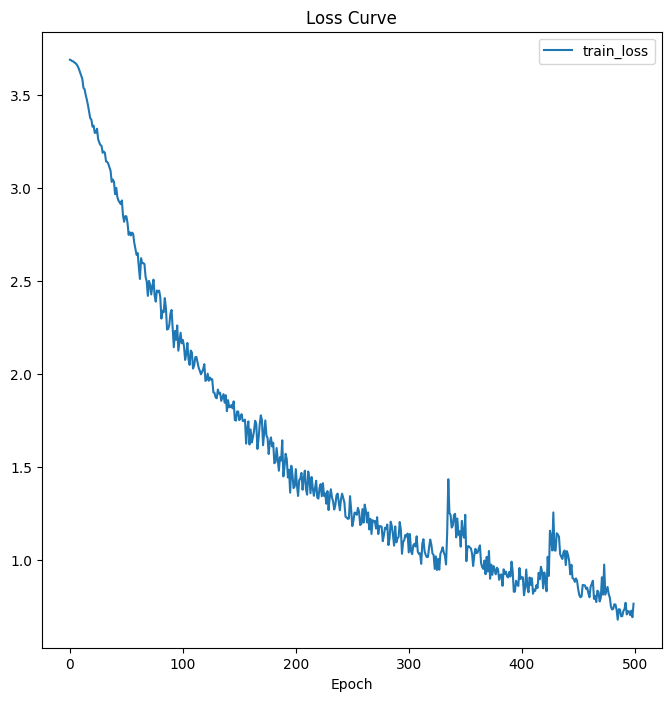

In [215]:
from matplotlib import pyplot as plt
plt.figure(figsize=(8,8))
plt.title("Loss Curve")
plt.plot(loss_logger, label='train_loss')
# plt.plot(val_loss, label='val_loss')
# plt.plot(accuracy_logger,label='accuracy')
plt.xlabel("Epoch")
plt.legend()
plt.show()

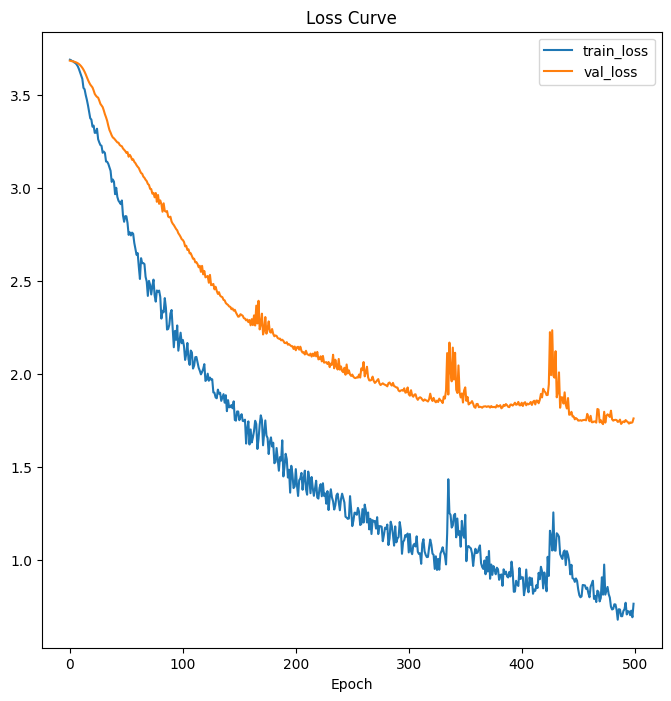

In [216]:
from matplotlib import pyplot as plt
plt.figure(figsize=(8,8))
plt.title("Loss Curve")
plt.plot(loss_logger, label='train_loss')
plt.plot(val_loss, label='val_loss')
# plt.plot(accuracy_logger,label='accuracy')
plt.xlabel("Epoch")
plt.legend()
plt.show()

In [217]:
def check_accuracy(loader, model, h, c):
    if loader == train_loader:
        print("Checking accuracy on training data")
    else:
        print("Checking accuracy on test data")  
          
    num_correct = 0
    num_samples = 0
    model.eval()
    
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device)
            y = y.to(device=device)
            # x = x.reshape(x.shape[0], -1)
            
            scores,h,c = model(x,h,c)
            _, predictions = scores.max(1)
            num_correct += (predictions == y).sum()
            num_samples += predictions.size(0)
            
        print(f"Got {num_correct} / {num_samples} with accuracy {float(num_correct)/float(num_samples)*100:.2f}")
        
    model.train()

In [218]:
h = torch.zeros(num_layers, batch_size, hidden_size).to(device)
c = torch.zeros(num_layers, batch_size, hidden_size).to(device)
check_accuracy(train_loader, model,h,c)
h = torch.zeros(num_layers, batch_size, hidden_size).to(device)
c = torch.zeros(num_layers, batch_size, hidden_size).to(device)
check_accuracy(test_loader, model,h,c)

Checking accuracy on training data
Got 84 / 96 with accuracy 87.50
Checking accuracy on test data
Got 20 / 32 with accuracy 62.50


### Confusion Matrix

In [219]:
def get_all_preds_labels(model, dataloader):
    model.eval()  # Set model to evaluation mode
    all_preds = []
    all_labels = []
    
    with torch.no_grad():  # No gradients needed for evaluation
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            # Initialize hidden and cell states
            batch_size = images.size(0)
            h = torch.zeros(model.num_layers, batch_size, model.hidden_size).to(device)
            c = torch.zeros(model.num_layers, batch_size, model.hidden_size).to(device)

            # Forward pass with LSTM, passing h and c separately
            outputs,h,c = model(images,h,c)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_preds), np.array(all_labels)


In [220]:
y_pred, y_true = get_all_preds_labels(model, test_loader)

In [221]:
y_pred

array([19,  1,  2,  3,  4, 18,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        2, 18, 19, 20, 21, 30, 11,  8, 30, 20, 19, 28,  8, 12, 28],
      dtype=int64)

In [222]:
y_true

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31],
      dtype=int64)

In [223]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
conf_matrix = confusion_matrix(y_true, y_pred)

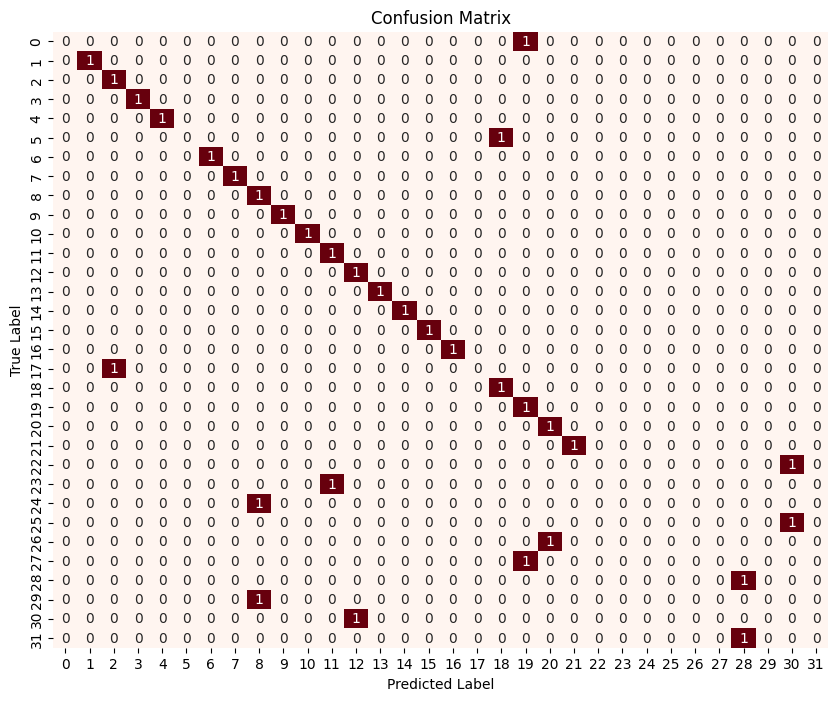

In [224]:
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Reds", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

### Real-Time Prediction

In [ ]:
import cv2
import numpy as np
import os
from matplotlib import pyplot as plt
import time
import mediapipe as mp 

In [ ]:
mp_holist = mp.solutions.holistic 
mp_draw = mp.solutions.drawing_utils

In [ ]:
def mediapipe_detection(img, model):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img.flags.writeable = False                 
    result = model.process(img)                 # Make prediction
    img.flags.writeable = True                   
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR) 
    return img, result

In [ ]:
def draw_landmarks(img, result):
    mp_draw.draw_landmarks(img, result.face_landmarks, mp_holist.FACEMESH_CONTOURS) # Draw face connections
    mp_draw.draw_landmarks(img, result.pose_landmarks, mp_holist.POSE_CONNECTIONS) # Draw pose connections
    mp_draw.draw_landmarks(img, result.left_hand_landmarks, mp_holist.HAND_CONNECTIONS) # Draw left hand connections
    mp_draw.draw_landmarks(img, result.right_hand_landmarks, mp_holist.HAND_CONNECTIONS) # Draw right hand connections

In [ ]:
def draw_styled_landmarks(img, result):
    mp_draw.draw_landmarks(img, result.face_landmarks, mp_holist.FACEMESH_CONTOURS, 
                             mp_draw.DrawingSpec(color=(80,110,10), thickness=1, circle_radius=1), # color the joint 
                             mp_draw.DrawingSpec(color=(80,256,121), thickness=1, circle_radius=1) #color the connection
                             ) 
    # mp_draw.draw_landmarks(img, result.face_landmarks, mp_holist.FACEMESH_CONTOURS, 
    #                          mp_draw.DrawingSpec(color=(80,110,10), thickness=1, circle_radius=1), # color the joint 
    #                          mp_draw.DrawingSpec(color=(80,256,121), thickness=1, circle_radius=1) #color the connection
    #                          ) 
    
    mp_draw.draw_landmarks(img, result.pose_landmarks, mp_holist.POSE_CONNECTIONS,
                             mp_draw.DrawingSpec(color=(80,22,10), thickness=2, circle_radius=4), 
                             mp_draw.DrawingSpec(color=(80,44,121), thickness=2, circle_radius=2)
                             ) 
    mp_draw.draw_landmarks(img, result.left_hand_landmarks, mp_holist.HAND_CONNECTIONS, 
                             mp_draw.DrawingSpec(color=(121,22,76), thickness=2, circle_radius=4), 
                             mp_draw.DrawingSpec(color=(121,44,250), thickness=2, circle_radius=2)
                             ) 
    mp_draw.draw_landmarks(img, result.right_hand_landmarks, mp_holist.HAND_CONNECTIONS, 
                             mp_draw.DrawingSpec(color=(245,117,66), thickness=2, circle_radius=4), 
                             mp_draw.DrawingSpec(color=(245,66,230), thickness=2, circle_radius=2)
                             ) 

In [ ]:
def extract_keypoints(results):
    pose=np.array([[res.x,res.y] for res in results.pose_landmarks.landmark]).flatten() if results.pose_landmarks else np.zeros(33*2)
    left_hnd=np.array([[res.x,res.y] for res in results.left_hand_landmarks.landmark]).flatten() if results.left_hand_landmarks else np.zeros(21*2)
    right_hnd=np.array([[res.x,res.y] for res in results.right_hand_landmarks.landmark]).flatten() if results.right_hand_landmarks else np.zeros(21*2)
    face=np.array([[res.x,res.y] for res in results.face_landmarks.landmark]).flatten() if results.face_landmarks else np.zeros(468*2)
    return np.concatenate([pose,left_hnd,right_hnd,face])
# concatenating for the model to detect the sign language

In [ ]:
cap = cv2.VideoCapture(0)
sequence = []
sequence_length = 160
h = torch.zeros(num_layers, 1, hidden_size).to(device)
c = torch.zeros(num_layers, 1, hidden_size).to(device)
# Set mediapipe model 
with mp_holist.Holistic(min_detection_confidence=0.5, min_tracking_confidence=0.5) as holistic:
    while cap.isOpened():

        ret, frame = cap.read()

        image, results = mediapipe_detection(frame, holistic)
        # print(results)

        keypoints = extract_keypoints(results)
        sequence.append(keypoints)

        if len(sequence) > sequence_length:
            sequence = []
    
        if len(sequence) == sequence_length:
            # Convert sequence to tensor
            input_tensor = torch.tensor([sequence], dtype=torch.float32)
        
            # Make predictions
            with torch.no_grad():
                prediction,h,c = model(input_tensor.to(device),h,c)
        
            # Decode and display the prediction
            predicted_class = torch.argmax(prediction, dim=1).item()
            print(f"Predicted Class: {predicted_class}")
            print(f"Class : {labels[predicted_class]}")
        
        draw_styled_landmarks(image, results)

        cv2.imshow('OpenCV Feed', image)

        if cv2.waitKey(10) & 0xFF == ord('q'):
            break
    cap.release()
    cv2.destroyAllWindows()

In [ ]:
cap.release()
cv2.destroyAllWindows()